# Kiểm thử Dự đoán Ảnh AI / Thật Đơn lẻ (Single Image Inference)

Notebook này được đặt độc lập bên ngoài thư mục `code/` để phục vụ mục đích kiểm thử trực quan và tiện lợi.

### Quy trình đánh giá:
1. **Tải 2 mô hình đã huấn luyện hoàn tất**:
   - **Nhánh Không gian (Spatial Branch)**: EfficientNet-B0 (`best_spatial.pth`)
   - **Nhánh Tần số Phổ (Spectral Branch)**: 2D FFT Residual CNN (`best_spectral.pth`)
2. **Tiền xử lý ảnh đồng bộ**:
   - Cắt ô pixel gốc `view_native` $224 \times 224$ (không resize bóp méo pixel hay phổ).
   - Chuẩn hóa ImageNet cho Spatial và tính phổ 2D FFT (DC removal + Z-score) cho Spectral.
3. **Trực quan hóa kết quả**:
   - Hiển thị Ảnh gốc, Vùng cắt `view_native` $224 \times 224$, và Bản đồ phổ tần số 2D FFT.
   - Xuất xác suất % AI sinh của từng nhánh và kết luận tổng hợp.

In [1]:
import os
import sys
from pathlib import Path

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ---------------------------------------------------------------------------
# Thiết lập đường dẫn import tới các module trong code/
# ---------------------------------------------------------------------------
NOTEBOOK_DIR = Path.cwd()
ROOT_DIR = NOTEBOOK_DIR if (NOTEBOOK_DIR / "code").exists() else NOTEBOOK_DIR.parent

BRANCH_DIR = ROOT_DIR / "code" / "system" / "branch"
PREPROC_DIR = ROOT_DIR / "code" / "pre_processing" / "pre_processing_all_and_branchs"
CHECKPOINT_DIR = ROOT_DIR / "code" / "system" / "checkpoints"

for p in (str(BRANCH_DIR), str(PREPROC_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from EfficientNet import SpatialBranch
from FFT import SpectralBranch
from pre_processing_for_all import CommonProcess
from pre_processing_EfficientNet import EfficientNetPreprocessor
from pre_processing_FFT import FFTPreprocessor

# Thiết bị tính toán (ưu tiên CUDA nếu có)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"-> Thiết bị tính toán: {device}")

-> Thiết bị tính toán: cuda


## 1. Nạp Trọng số Tốt nhất (Best Checkpoints) của 2 Nhánh

In [2]:
spatial_ckpt_path = CHECKPOINT_DIR / "spatial_baseline" / "best_spatial.pth"
spectral_ckpt_path = CHECKPOINT_DIR / "spectral_baseline" / "best_spectral.pth"

print("-> Đang nạp mô hình Spatial (EfficientNet-B0)...")
spatial_model = SpatialBranch(pretrained=False, dropout=0.2)
s_ckpt = torch.load(spatial_ckpt_path, map_location="cpu", weights_only=False)
spatial_model.load_state_dict(s_ckpt["model_state_dict"])
spatial_model.to(device).eval()
print(f"   + Đã nạp thành công best_spatial.pth (Epoch {s_ckpt.get('epoch', '?')})")

print("-> Đang nạp mô hình Spectral (FFT Residual CNN)...")
spectral_model = SpectralBranch(dropout=0.3)
f_ckpt = torch.load(spectral_ckpt_path, map_location="cpu", weights_only=False)
spectral_model.load_state_dict(f_ckpt["model_state_dict"])
spectral_model.to(device).eval()
print(f"   + Đã nạp thành công best_spectral.pth (Epoch {f_ckpt.get('epoch', '?')})")

# Khởi tạo sẵn các bộ tiền xử lý chuẩn đánh giá
prep_common = CommonProcess(mode="eval")
prep_spatial = EfficientNetPreprocessor(view_mode="native", normalize=True)
prep_spectral = FFTPreprocessor(mode="raw", use_hann=False, remove_dc=True, normalize=True)
print("-> Hoàn tất sẵn sàng dự đoán!")

-> Đang nạp mô hình Spatial (EfficientNet-B0)...
   + Đã nạp thành công best_spatial.pth (Epoch 15)
-> Đang nạp mô hình Spectral (FFT Residual CNN)...
   + Đã nạp thành công best_spectral.pth (Epoch 29)
-> Hoàn tất sẵn sàng dự đoán!


## 2. Hàm Dự đoán & Trực quan hóa Ảnh đơn lẻ

In [3]:
def inspect_and_predict(image_path: str, threshold: float = 0.5):
    """
    Đọc ảnh, hiển thị trực quan 3 góc nhìn (Gốc, Crop Native 224, Phổ 2D FFT) 
    và xuất kết quả dự đoán của 2 nhánh mô hình.
    """
    path = Path(image_path)
    if not path.is_absolute():
        path = ROOT_DIR / path
        
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy ảnh tại: {path}")

    # 1. Tiền xử lý chung
    common_out = prep_common(str(path))
    orig_img = common_out["view_global"]
    view_native = common_out["view_native"]

    # 2. Tensor hóa cho 2 nhánh
    tensor_spatial = prep_spatial(common_out).unsqueeze(0).to(device)
    tensor_spectral = prep_spectral(common_out).unsqueeze(0).to(device)

    # 3. Suy luận qua mô hình
    with torch.no_grad():
        logit_sp = spatial_model(tensor_spatial).item()
        prob_ai_sp = float(torch.sigmoid(torch.tensor(logit_sp)).item())

        logit_spec = spectral_model(tensor_spectral).item()
        prob_ai_spec = float(torch.sigmoid(torch.tensor(logit_spec)).item())

    prob_ai_ensemble = (prob_ai_sp + prob_ai_spec) / 2.0

    # 4. Trực quan hóa hình ảnh
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Ảnh gốc
    axes[0].imshow(orig_img)
    axes[0].set_title(f"1. Ảnh gốc\n({common_out['orig_size'][0]}x{common_out['orig_size'][1]} px)", fontsize=11, fontweight="bold")
    axes[0].axis("off")

    # Vùng crop 224x224 (view_native)
    axes[1].imshow(view_native)
    crop_box = common_out["native_crop_box"]
    axes[1].set_title(f"2. Vùng cắt Native 224x224\nBox: {crop_box}", fontsize=11, fontweight="bold")
    axes[1].axis("off")

    # Phổ tần số 2D FFT
    fft_map = tensor_spectral.squeeze().cpu().numpy()
    im_fft = axes[2].imshow(fft_map, cmap="magma")
    axes[2].set_title("3. Bản đồ Phổ 2D Fourier (FFT)\n(Đã khử DC & Z-Score)", fontsize=11, fontweight="bold")
    axes[2].axis("off")
    fig.colorbar(im_fft, ax=axes[2], fraction=0.046, pad=0.04)

    plt.suptitle(f"Kiểm thử mẫu: {path.name}", fontsize=13, fontweight="bold", y=0.98)
    plt.tight_layout()
    plt.show()

    # 5. In bảng kết quả đánh giá
    verdict_sp = "AI GENERATED" if prob_ai_sp >= threshold else "REAL (MS_COCO)"
    verdict_spec = "AI GENERATED" if prob_ai_spec >= threshold else "REAL (MS_COCO)"
    verdict_ens = "AI GENERATED" if prob_ai_ensemble >= threshold else "REAL (MS_COCO)"

    print("=" * 75)
    print(f"{ 'NHÁNH MÔ HÌNH':<30} | {'XÁC SUẤT AI':<14} | {'XÁC SUẤT THẬT':<14} | {'KẾT LUẬN'}")
    print("-" * 75)
    print(f"{ '[1] Spatial (EfficientNet-B0)':<30} | {prob_ai_sp * 100:>11.2f}% | {(1-prob_ai_sp)*100:>11.2f}% | {verdict_sp}")
    print(f"{ '[2] Spectral (FFT Residual CNN)':<30} | {prob_ai_spec * 100:>11.2f}% | {(1-prob_ai_spec)*100:>11.2f}% | {verdict_spec}")
    print("-" * 75)
    print(f"{ '[3] KẾT HỢP (Ensemble Trung bình)':<30} | {prob_ai_ensemble * 100:>11.2f}% | {(1-prob_ai_ensemble)*100:>11.2f}% | >>> {verdict_ens} <<<")
    print("=" * 75)

    return {
        "spatial_ai_prob": prob_ai_sp,
        "spectral_ai_prob": prob_ai_spec,
        "ensemble_prob": prob_ai_ensemble,
        "verdict": verdict_ens,
    }

## 3. Chạy Kiểm thử Thử nghiệm

Bạn chỉ cần thay đổi đường dẫn ở biến `TEST_IMAGE_PATH` thành đường dẫn ảnh bạn muốn kiểm tra (ảnh từ dataset hoặc ảnh bên ngoài bất kỳ).

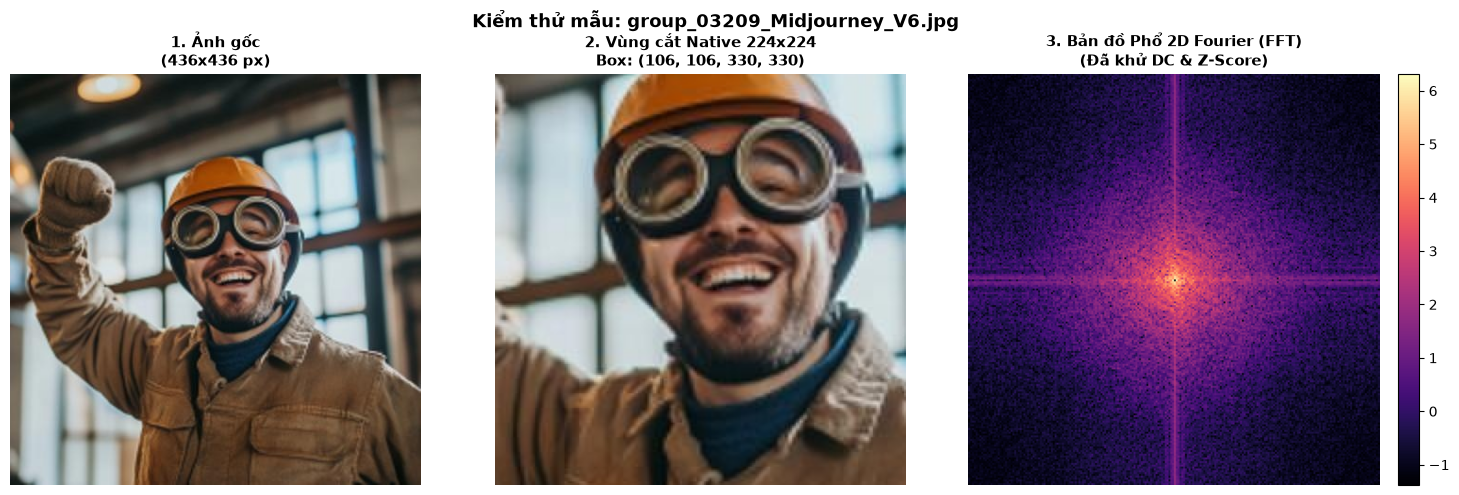

NHÁNH MÔ HÌNH                  | XÁC SUẤT AI    | XÁC SUẤT THẬT  | KẾT LUẬN
---------------------------------------------------------------------------
[1] Spatial (EfficientNet-B0)  |       99.92% |        0.08% | AI GENERATED
[2] Spectral (FFT Residual CNN) |       86.24% |       13.76% | AI GENERATED
---------------------------------------------------------------------------
[3] KẾT HỢP (Ensemble Trung bình) |       93.08% |        6.92% | >>> AI GENERATED <<<


In [20]:
# === TEST 3: ĐƯỜNG DẪN ẢNH TÙY Ý CỦA BẠN ===
# Bạn có thể dán đường dẫn ảnh bất kỳ từ máy tính của bạn vào đây:
MY_CUSTOM_IMAGE = r"D:\nam_4\DATN\dataset\Defactify_dataset\train\ai\group_03209_Midjourney_V6.jpg"

if os.path.exists(MY_CUSTOM_IMAGE) or (ROOT_DIR / MY_CUSTOM_IMAGE).exists():
    inspect_and_predict(MY_CUSTOM_IMAGE)
else:
    print(f"Hãy nhập đường dẫn ảnh hợp lệ vào MY_CUSTOM_IMAGE!")